In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_HEIGHT = 256
IMG_WIDTH = 256
BATCH_SIZE = 32
TRAIN_DIR = "folder/spec_s_no_fear/train"
VAL_DIR = "folder/spec_s_no_fear/val"
TEST_DIR = "folder/spec_s_no_fear/test"

def create_datasets(train_dir, val_dir, test_dir, img_height, img_width, batch_size):
    normalization_layer = layers.Rescaling(1.0 / 127.5, offset=-1)  # Scale to [-1, 1]
    
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, image_size=(img_height, img_width), batch_size=batch_size, shuffle=True
    ).map(lambda x, y: (normalization_layer(x), y))
    
    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir, image_size=(img_height, img_width), batch_size=batch_size
    ).map(lambda x, y: (normalization_layer(x), y))
    
    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir, image_size=(img_height, img_width), batch_size=batch_size
    ).map(lambda x, y: (normalization_layer(x), y))
    
    train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = create_datasets(TRAIN_DIR, VAL_DIR, TEST_DIR, IMG_HEIGHT, IMG_WIDTH, BATCH_SIZE)

def se_block(input_tensor, reduction_ratio=16):
    """ Squeeze-and-Excitation block for channel attention """
    channels = input_tensor.shape[-1]
    se = layers.GlobalAveragePooling2D()(input_tensor)
    se = layers.Dense(channels // reduction_ratio, activation='relu')(se)
    se = layers.Dense(channels, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, channels))(se)
    return layers.Multiply()([input_tensor, se])

def build_model(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)
    
    # First Conv Block
    x = layers.Conv2D(64, (3, 3))(inputs)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.35)(x)
    
    # Second Conv Block with Attention
    x = layers.Conv2D(128, (3, 3))(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = se_block(x)  # Add SE block
    x = layers.Dropout(0.35)(x)
    
    # Third Conv Block
    x = layers.Conv2D(256, (3, 3))(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.45)(x)
    
    # Fourth Conv Block with Attention
    x = layers.Conv2D(256, (3, 3))(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = se_block(x)  # Add SE block
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.45)(x)
    
    # Fifth Conv Block
    x = layers.Conv2D(512, (3, 3))(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.5)(x)
    
    # Fully Connected Layers
    x = layers.Flatten()(x)
    x = layers.Dense(512)(x)
    x = tf.keras.layers.Activation('swish')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256)(x)
    x = tf.keras.layers.Activation('swish')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    return models.Model(inputs, outputs)

class_names = raw_test_ds.class_names

class_name_to_index = {name: idx for idx, name in enumerate(class_names)}
angry_index = class_name_to_index["Angry"]
happy_index = class_name_to_index["Happy"]
sad_index = class_name_to_index["Sad"]
neutral_index = class_name_to_index["Neutral"]

def penalized_loss(y_true, y_pred):
    # Convert y_true to one-hot encoding
    y_true_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=len(class_names))
    
    base_loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    
    misclassified_as_happy = tf.cast(
        tf.logical_and(
            tf.equal(y_true, angry_index), 
            tf.equal(tf.argmax(y_pred, axis=-1), happy_index) 
        ),
        tf.float32
    )

    penalty = 2.0 * misclassified_as_happy
 
    return base_loss + penalty

input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)
num_classes = 4
model = build_model(input_shape, num_classes)

optimizer =  tf.keras.optimizers.Nadam(learning_rate=0.001)

model.compile(optimizer=optimizer, 
              loss=penalized_loss, 
              metrics=['accuracy'])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.4, patience=3)
model_checkpoint = tf.keras.callbacks.ModelCheckpoint('pen1_model.h5', save_best_only=True)

EPOCHS = 50
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1, 
                    callbacks=[early_stopping, model_checkpoint, lr_scheduler])

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test Accuracy: {test_accuracy:.2f}")

NotFoundError: Could not find directory folder/spec_s_no_fear/train

Layer Name: conv2d_208
Filters Shape: (3, 3, 3, 64)
Figure saved as 'conv_filters.png'.


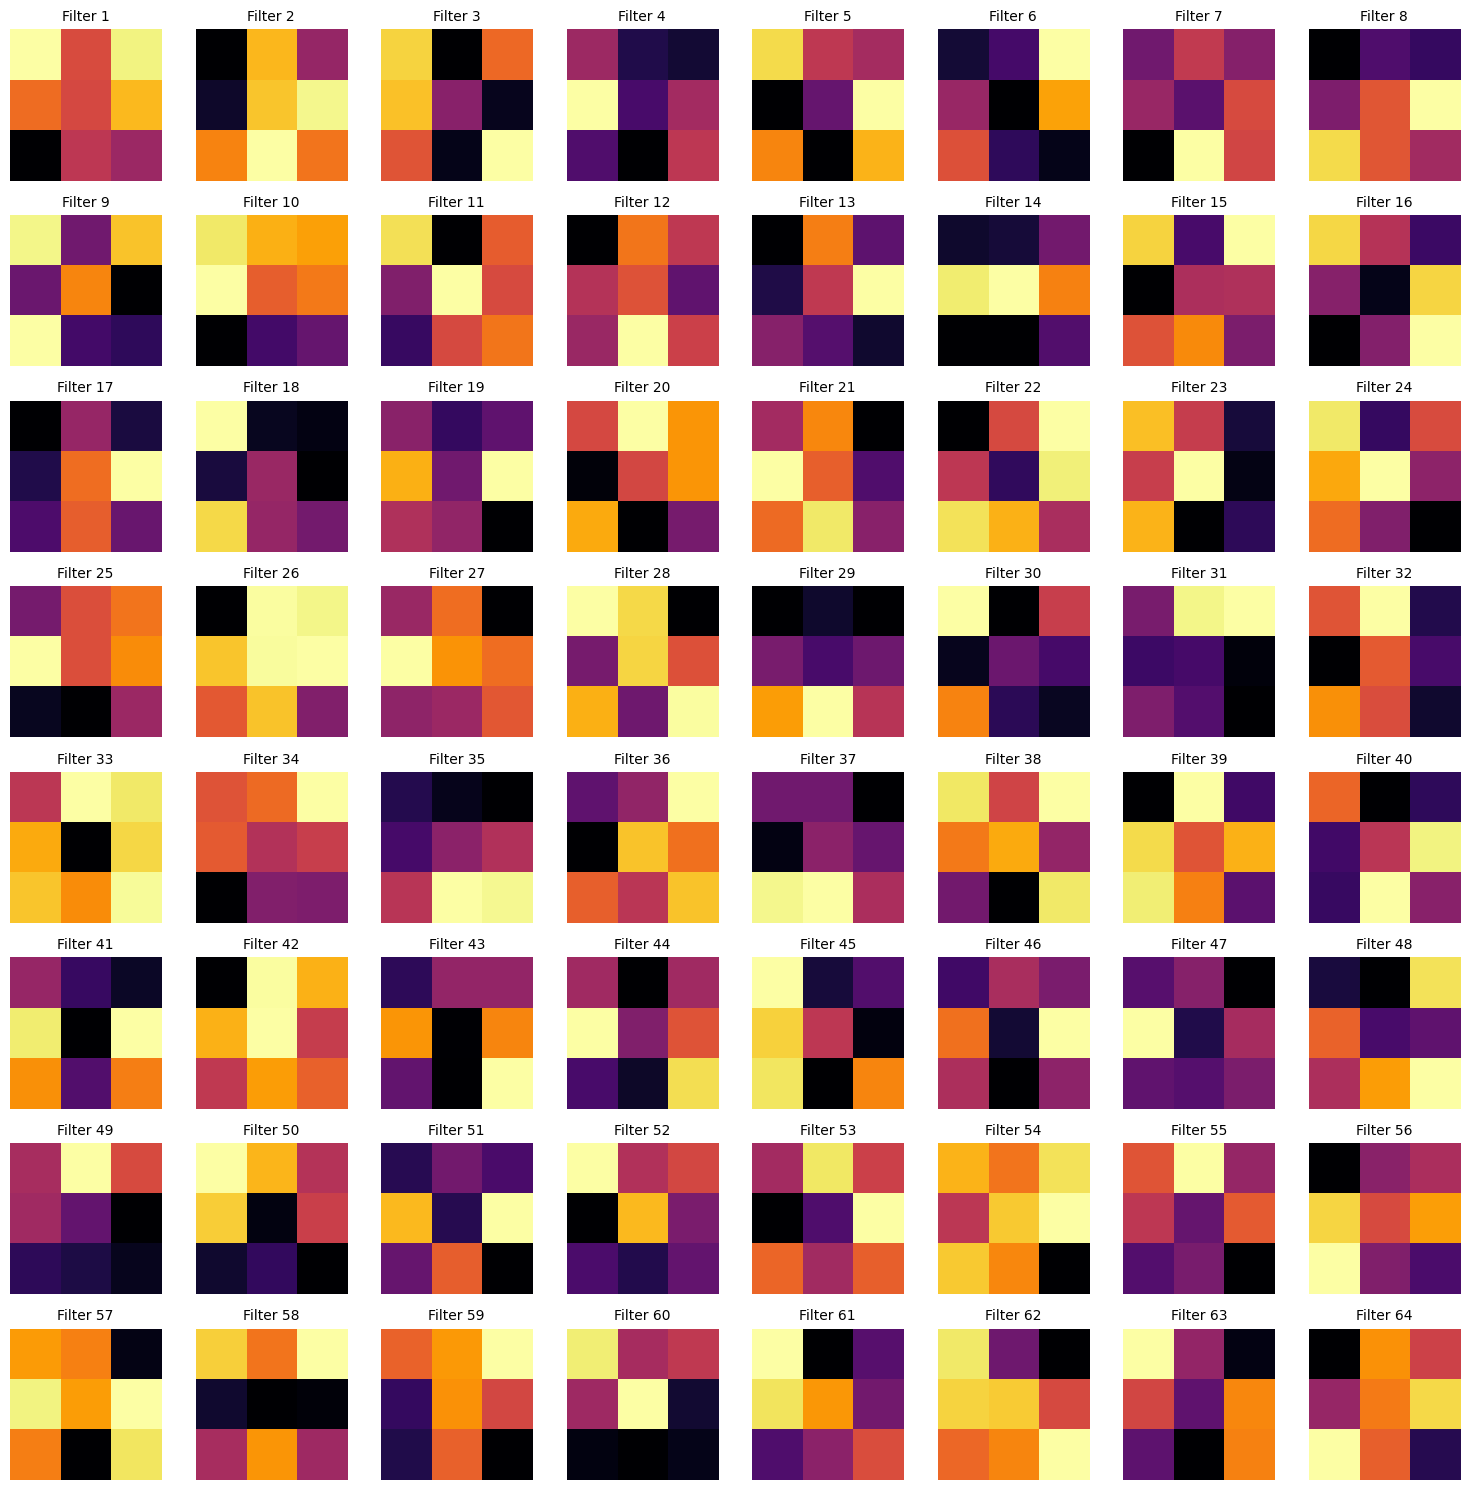

In [15]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Load the model without compiling
model = tf.keras.models.load_model('pen1_model.h5', compile=False)

# Get the first convolutional layer
first_conv_layer = None
for layer in model.layers:
    if 'conv' in layer.name:  # Check if it's a convolutional layer
        first_conv_layer = layer
        break  # Exit the loop after finding the first convolutional layer

if first_conv_layer:
    filters, biases = first_conv_layer.get_weights()
    print(f"Layer Name: {first_conv_layer.name}")
    print(f"Filters Shape: {filters.shape}")  # (height, width, input_channels, num_filters)
    
    # Visualize the filters of the first convolutional layer
    num_filters = filters.shape[-1]
    
    # Calculate number of rows and columns for the grid layout (adjust as needed)
    rows = int(np.sqrt(num_filters))
    cols = int(np.ceil(num_filters / rows))
    
    # Increase the figure size for better visualization
    fig, axes = plt.subplots(rows, cols, figsize=(15, 15))  # Adjust figure size
    
    # Flatten axes array for easier indexing
    axes = axes.flatten()
    
    for i in range(num_filters):
        f = filters[:, :, :, i]
        
        # Normalize the filter values to [0, 1] for proper visualization
        f_min, f_max = f.min(), f.max()
        f_normalized = (f - f_min) / (f_max - f_min)
        
        # Plot each filter using the 'inferno' colormap (similar to mel spectrogram colors)
        axes[i].imshow(f_normalized[:, :, 0], cmap='inferno')  # Assuming single channel filter
        axes[i].axis('off')  # Turn off axis for better appearance
        
        # Optional: Add a title with the filter index
        axes[i].set_title(f"Filter {i+1}", fontsize=10)
    
    # Hide any unused axes
    for i in range(num_filters, len(axes)):
        axes[i].axis('off')
    
    # Adjust layout to make sure there's no overlap
    plt.tight_layout()
    
    # Save the figure to a file
    plt.savefig('conv_filters.png', dpi=300)  # Save as PNG, with 300 DPI resolution
    print("Figure saved as 'conv_filters.png'.")
    
    plt.show()
else:
    print("No convolutional layer found in the model.")
